# MLOps Assignment 01 — Heart Disease Classification

This notebook covers dataset acquisition, cleaning, EDA, model comparison, cross-validation, MLflow tracking, and artifact creation. After installing `requirements-dev.txt`, run it from the repository root or open it from the `notebooks/` folder; it resolves the project root automatically.

**Safety note:** Educational demonstration only; not for clinical use. Run every cell and use actual outputs in your report.

## 1. Imports and reproducibility

In [1]:
import json
import os
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import mlflow
import mlflow.sklearn
import pandas as pd
import seaborn as sns
from mlflow.models import infer_signature
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    RocCurveDisplay,
    accuracy_score,
    classification_report,
    precision_score,
    recall_score,
    roc_auc_score,
)
from sklearn.model_selection import GridSearchCV, StratifiedKFold, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

PROJECT_ROOT = Path.cwd()
if not (PROJECT_ROOT / "src").is_dir():
    PROJECT_ROOT = PROJECT_ROOT.parent
if not (PROJECT_ROOT / "src").is_dir():
    raise FileNotFoundError("Run this notebook from the project root or its notebooks folder.")
os.chdir(PROJECT_ROOT)
sys.path.insert(0, str(PROJECT_ROOT))

from src.data import FEATURES, TARGET, clean_frame, load_uci_heart_disease

RANDOM_STATE = 42
Path("data").mkdir(exist_ok=True)
Path("artifacts/plots").mkdir(parents=True, exist_ok=True)
sns.set_theme(context="notebook", style="whitegrid")

## 2. Acquire and clean the dataset

In [2]:
data_path = Path("data/heart_disease.csv")
if data_path.exists():
    raw = pd.read_csv(data_path)
else:
    raw = load_uci_heart_disease()
df = clean_frame(raw)
df.to_csv(data_path, index=False)
print("Shape:", df.shape)
display(df.head())
display(df.info())
display(df.isna().sum().sort_values(ascending=False).to_frame("missing_count"))
print("Target distribution:")
display(df[TARGET].value_counts().sort_index().rename(index={0: "absence", 1: "presence"}))

Shape: (303, 14)


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,63,1,1,145,233,1,2,150,0,2.3,3,0.0,6.0,0
1,67,1,4,160,286,0,2,108,1,1.5,2,3.0,3.0,1
2,67,1,4,120,229,0,2,129,1,2.6,2,2.0,7.0,1
3,37,1,3,130,250,0,0,187,0,3.5,3,0.0,3.0,0
4,41,0,2,130,204,0,2,172,0,1.4,1,0.0,3.0,0


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 303 entries, 0 to 302
Data columns (total 14 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       303 non-null    int64  
 1   sex       303 non-null    int64  
 2   cp        303 non-null    int64  
 3   trestbps  303 non-null    int64  
 4   chol      303 non-null    int64  
 5   fbs       303 non-null    int64  
 6   restecg   303 non-null    int64  
 7   thalach   303 non-null    int64  
 8   exang     303 non-null    int64  
 9   oldpeak   303 non-null    float64
 10  slope     303 non-null    int64  
 11  ca        299 non-null    float64
 12  thal      301 non-null    float64
 13  target    303 non-null    int64  
dtypes: float64(3), int64(11)
memory usage: 33.3 KB


None

,missing_count
ca,4
thal,2
cp,0
trestbps,0
age,0
sex,0
fbs,0
chol,0
restecg,0
thalach,0


Target distribution:


target
absence     164
presence    139
Name: count, dtype: int64

## 3. Exploratory data analysis

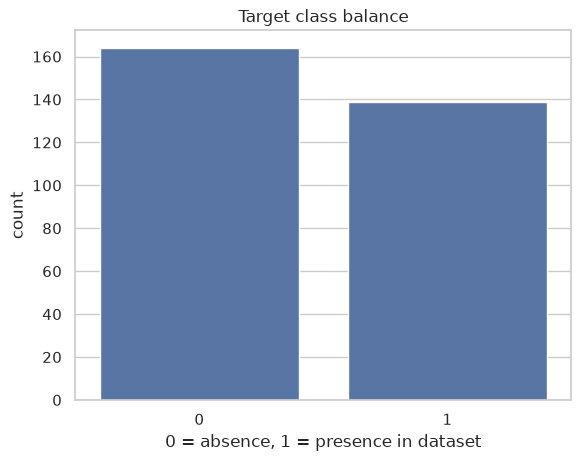

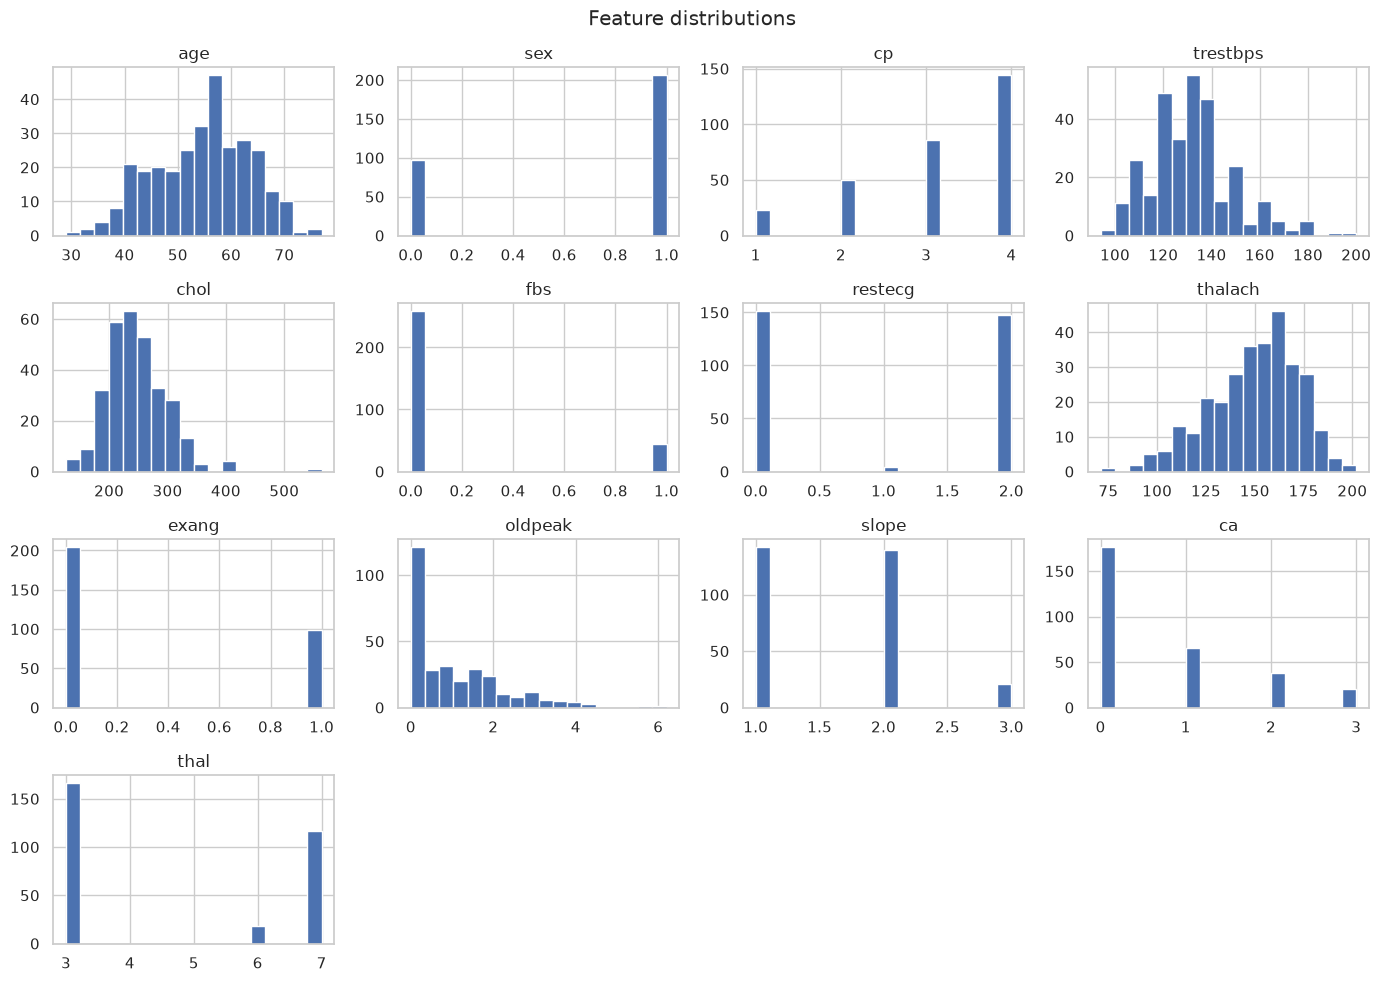

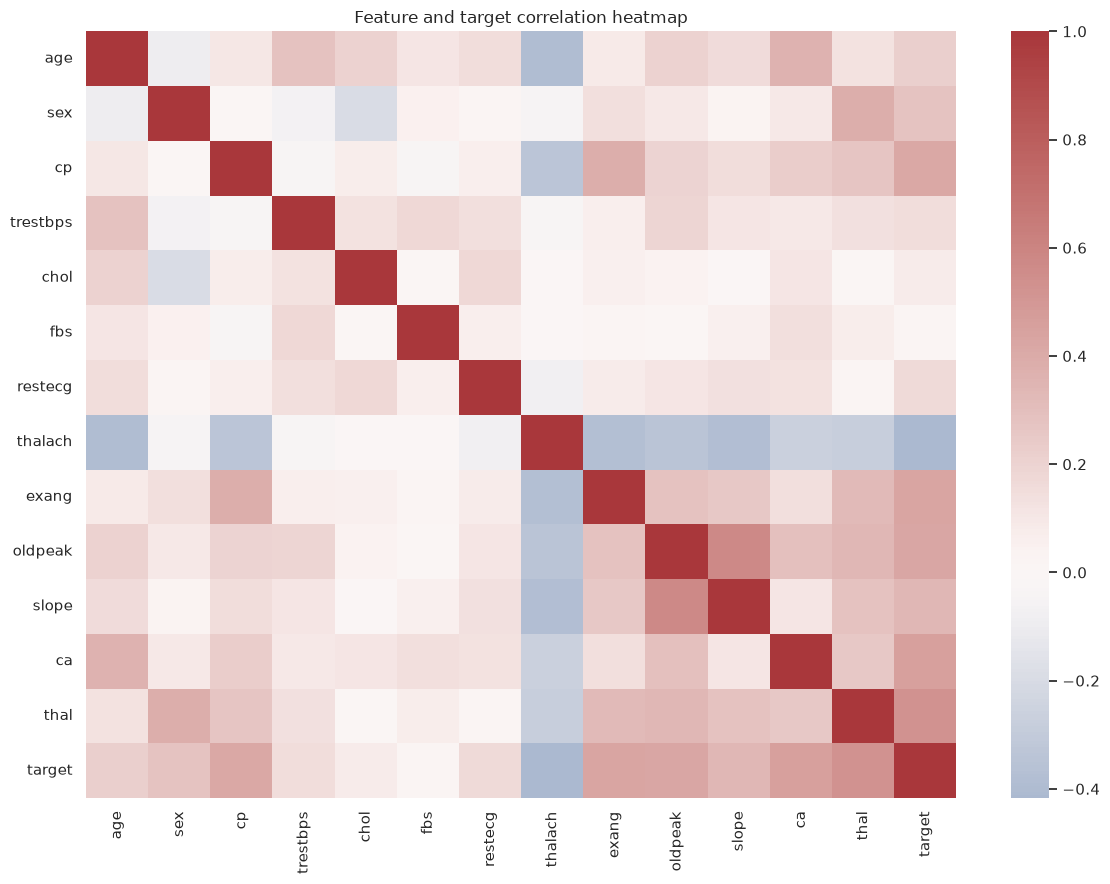

In [3]:
ax = sns.countplot(data=df, x=TARGET)
ax.set_title("Target class balance")
ax.set_xlabel("0 = absence, 1 = presence in dataset")
plt.show()

df[FEATURES].hist(figsize=(14, 10), bins=18)
plt.suptitle("Feature distributions")
plt.tight_layout()
plt.show()

plt.figure(figsize=(12, 9))
sns.heatmap(df.corr(numeric_only=True), cmap="vlag", center=0)
plt.title("Feature and target correlation heatmap")
plt.tight_layout()
plt.show()

**Your observations:** Record at least three observations from the actual plots. Do not assume correlations imply causation.

## 4. Train/test split and preprocessing

In [4]:
X, y = df[FEATURES], df[TARGET]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y
)
preprocessor = ColumnTransformer([
    ("numeric", Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
    ]), FEATURES)
])
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
print("Train:", X_train.shape, "Test:", X_test.shape)
print("Train class fractions:")
display(y_train.value_counts(normalize=True).sort_index())

Train: (242, 13) Test: (61, 13)
Train class fractions:


target
0    0.541322
1    0.458678
Name: proportion, dtype: float64

## 5. Train and compare at least two models

In [5]:
candidates = {
    "logistic_regression": (
        Pipeline([("preprocess", preprocessor), ("classifier", LogisticRegression(max_iter=2000, random_state=RANDOM_STATE))]),
        {"classifier__C": [0.1, 1.0, 10.0]},
    ),
    "random_forest": (
        Pipeline([("preprocess", preprocessor), ("classifier", RandomForestClassifier(random_state=RANDOM_STATE, class_weight="balanced"))]),
        {"classifier__n_estimators": [100, 250], "classifier__max_depth": [None, 4, 8]},
    ),
}

mlflow.set_tracking_uri("sqlite:///mlruns/mlflow.db")
mlflow.set_experiment("uci-heart-disease-classification")
results = []
fitted_models = {}
for name, (pipeline, param_grid) in candidates.items():
    with mlflow.start_run(run_name=name) as run:
        search = GridSearchCV(pipeline, param_grid, cv=cv, scoring="roc_auc", n_jobs=-1, refit=True, error_score="raise")
        search.fit(X_train, y_train)
        model = search.best_estimator_
        y_pred = model.predict(X_test)
        y_prob = model.predict_proba(X_test)[:, 1]
        metrics = {
            "cv_best_roc_auc": float(search.best_score_),
            "test_accuracy": float(accuracy_score(y_test, y_pred)),
            "test_precision": float(precision_score(y_test, y_pred, zero_division=0)),
            "test_recall": float(recall_score(y_test, y_pred, zero_division=0)),
            "test_roc_auc": float(roc_auc_score(y_test, y_prob)),
        }
        mlflow.log_param("model", name)
        mlflow.log_params(search.best_params_)
        mlflow.log_param("random_state", RANDOM_STATE)
        mlflow.log_param("cv_folds", 5)
        mlflow.log_metrics(metrics)
        mlflow.log_text(classification_report(y_test, y_pred, zero_division=0), "classification_report.txt")
        input_example = X_train.head(5).astype("float64")
        signature = infer_signature(input_example, model.predict(input_example))
        mlflow.sklearn.log_model(
            model,
            name="model",
            signature=signature,
            input_example=input_example,
            serialization_format=mlflow.sklearn.SERIALIZATION_FORMAT_CLOUDPICKLE,
        )
        results.append({"run_id": run.info.run_id, "model": name, "best_params": search.best_params_, **metrics})
        fitted_models[name] = model
        print(name, metrics)
        print(classification_report(y_test, y_pred, zero_division=0))

2026/10/20 21:36:20 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html


logistic_regression {'cv_best_roc_auc': 0.9000754479015349, 'test_accuracy': 0.8524590163934426, 'test_precision': 0.8064516129032258, 'test_recall': 0.8928571428571429, 'test_roc_auc': 0.9577922077922079}
              precision    recall  f1-score   support

           0       0.90      0.82      0.86        33
           1       0.81      0.89      0.85        28

    accuracy                           0.85        61
   macro avg       0.85      0.86      0.85        61
weighted avg       0.86      0.85      0.85        61



2026/10/20 21:37:04 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html


random_forest {'cv_best_roc_auc': 0.8903297185905881, 'test_accuracy': 0.8852459016393442, 'test_precision': 0.8387096774193549, 'test_recall': 0.9285714285714286, 'test_roc_auc': 0.9577922077922078}
              precision    recall  f1-score   support

           0       0.93      0.85      0.89        33
           1       0.84      0.93      0.88        28

    accuracy                           0.89        61
   macro avg       0.89      0.89      0.89        61
weighted avg       0.89      0.89      0.89        61



## 6. Compare metrics and inspect ROC curves

,run_id,model,best_params,cv_best_roc_auc,test_accuracy,test_precision,test_recall,test_roc_auc
0,68aa105c03cc4928aa937ffea824a388,logistic_regression,{'classifier__C': 0.1},0.900075,0.852459,0.806452,0.892857,0.957792
1,0c664d12d0ea4089aaaeaf95f2bcee2e,random_forest,"{'classifier__max_depth': 4, 'classifier__n_es...",0.890330,0.885246,0.838710,0.928571,0.957792


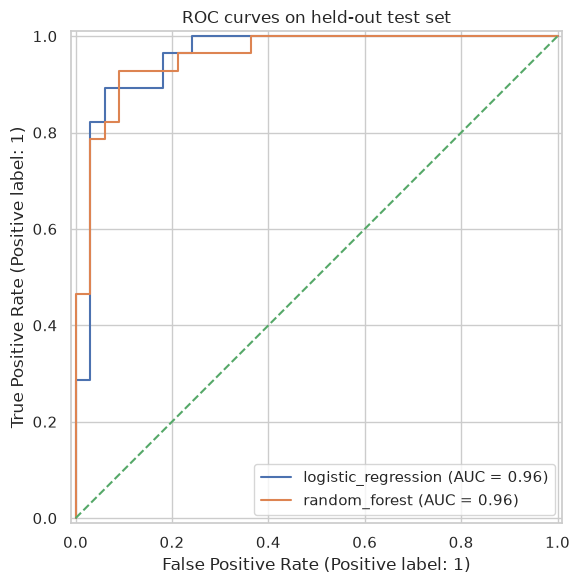

Selected model for this run: logistic_regression
Selection is based on mean cross-validation ROC-AUC; held-out test metrics are reserved for final evaluation.


In [6]:
results_df = pd.DataFrame(results).sort_values("cv_best_roc_auc", ascending=False)
display(results_df)
plt.figure(figsize=(7, 6))
ax = plt.gca()
for name, model in fitted_models.items():
    RocCurveDisplay.from_estimator(model, X_test, y_test, name=name, ax=ax)
ax.plot([0, 1], [0, 1], linestyle="--", label="chance")
ax.set_title("ROC curves on held-out test set")
plt.tight_layout()
plt.show()

best_name = results_df.iloc[0]["model"]
best_model = fitted_models[best_name]
print("Selected model for this run:", best_name)
print("Selection is based on mean cross-validation ROC-AUC; held-out test metrics are reserved for final evaluation.")

## 7. Confusion matrix and save artifacts

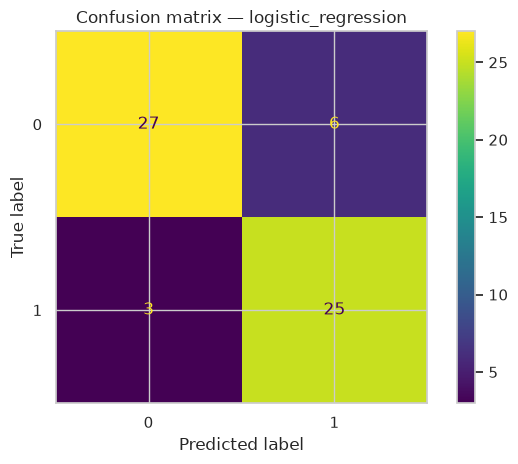

Saved artifacts/model.joblib and artifacts/metrics.json


,value
selected_model,logistic_regression
selection_metric,mean cross-validation ROC-AUC
results,[{'run_id': '68aa105c03cc4928aa937ffea824a388'...
feature_order,"[age, sex, cp, trestbps, chol, fbs, restecg, t..."
warning,Educational dataset only; not for clinical use.


In [7]:
Path("artifacts").mkdir(exist_ok=True)
ConfusionMatrixDisplay.from_estimator(best_model, X_test, y_test)
plt.title(f"Confusion matrix — {best_name}")
plt.tight_layout()
plt.savefig("artifacts/plots/best_confusion_matrix.png", dpi=150)
plt.show()

import joblib

joblib.dump(best_model, "artifacts/model.joblib")
summary = {"selected_model": best_name, "selection_metric": "mean cross-validation ROC-AUC",
           "results": results, "feature_order": FEATURES,
           "warning": "Educational dataset only; not for clinical use."}
Path("artifacts/metrics.json").write_text(json.dumps(summary, indent=2))
print("Saved artifacts/model.joblib and artifacts/metrics.json")
display(pd.Series(json.loads(Path("artifacts/metrics.json").read_text()), name="value").to_frame())

## 8. Experiment tracking and conclusions

In [8]:
print("MLflow tracking database: ./mlruns/mlflow.db")
print("Start UI from repository root with: mlflow ui --backend-store-uri sqlite:///mlruns/mlflow.db --host 127.0.0.1 --port 5000")
print("Open http://127.0.0.1:5000 and capture a screenshot of your actual runs.")

MLflow tracking database: ./mlruns/mlflow.db
Start UI from repository root with: mlflow ui --backend-store-uri sqlite:///mlruns/mlflow.db --host 127.0.0.1 --port 5000
Open http://127.0.0.1:5000 and capture a screenshot of your actual runs.


### Reflection (complete after running)
- Which model performed better on cross-validation ROC-AUC?
- Did the ranking change on the held-out test set?
- Which metric matters most for this educational problem, and why?
- What are the dataset-size, representativeness, calibration, and clinical-use limitations?
- What changes would you test next without leaking test-set information?